# 第15讲：从数清一个词，到服务分析

每一步先看输入、自己计算，再检查输出。原始CSV已经在data/raw中。课堂共54页，先做词频，再做TF-IDF，随后分类和简报。

## 1. 打开真实评论（课件4—6页）

先核对总行数，再读三段真实摘句。A合并同一评论的两处原句，手算只数显示摘句。

In [1]:
from pathlib import Path
from collections import Counter
import json, re
import pandas as pd
import numpy as np
from analysis import load_data, classroom_excerpts, tokenize, STOPWORDS, ASPECTS
parts=load_data()
df=pd.concat(parts.values(),ignore_index=True)
assert df.shape==(46730,22)
print('行列数：',df.shape)
excerpts=classroom_excerpts(df)
for e in excerpts: print(e['name'],e['id'],e['text'])

行列数： (46730, 22)
A 43901 味道有点像之前在大通冰室喝的丝袜奶茶……不过味道还是不错的
B 33204 环境还可以，上菜速度适中，菜量很少，味道还行
C 20264 牛角包味道很不错，其他两个都有点腻，感觉一般，不过团购还是很划算的。牛角包很不错。推荐。


## 2. 分词、计数与词频（课件6—10页）

先人工数牛角包，再运行Counter。每出现一次加1，重复仍计入。

In [2]:
words=['牛角包','味道','很','不错','牛角包']
counts=Counter(words)
print(counts)
assert counts['牛角包']==2
print(tokenize('牛角包味道很不错。',remove_stopwords=False))

Counter({'牛角包': 2, '味道': 1, '很': 1, '不错': 1})
['牛角包', '味道', '很', '不错']


In [3]:
toy_words=['味道','牛角包','上菜速度']
toy_texts=[e['text'] for e in excerpts]
toy_counts=np.array([[Counter(tokenize(t))[w] for w in toy_words] for t in toy_texts])
count_table=pd.DataFrame(toy_counts,index=['A','B','C'],columns=toy_words)
assert toy_counts.tolist()==[[2,0,0],[1,0,1],[1,2,0]]
display(count_table)
print('合计：',toy_counts.sum(axis=0),'，指定三词共',toy_counts.sum(),'次')
print('在指定三词中的相对频率：',toy_counts.sum(axis=0)/toy_counts.sum())

,味道,牛角包,上菜速度
A,2,0,0
B,1,0,1
C,1,2,0


合计： [4 2 1] ，指定三词共 7 次
在指定三词中的相对频率： [0.57142857 0.28571429 0.14285714]


## 3. 全量词频、停用词与领域词（课件11—15页）

先保留常见虚词，再用公开的停用词表整理。完整分词需要一些时间。否定词继续保留。

In [4]:
all_words=[]
raw_counts=Counter()
for review in df.review:
    words=tokenize(review,remove_stopwords=False)
    all_words.append(words)
    raw_counts.update(words)
raw_table=pd.DataFrame(raw_counts.most_common(),columns=['word','count'])
raw_table.head(12)

,word,count
0,的,487778
1,了,221218
2,是,135971
3,很,118988
4,吃,104112
5,也,93904
6,都,77017
7,就,67874
8,有,65294
9,我,61627


In [5]:
print('停用词表：',sorted(STOPWORDS))
kept_words=[[w for w in words if w not in STOPWORDS] for words in all_words]
word_counts=Counter(w for words in kept_words for w in words)
total_tokens=sum(word_counts.values())
frequency=pd.DataFrame([{'word':w,'count':n,'relative_frequency':n/total_tokens} for w,n in word_counts.most_common()])
print('全部保留词的出现总次数：',total_tokens)
frequency.head(12)

停用词表： ['一下', '一个', '一些', '一家', '不过', '也', '了', '什么', '他们', '但是', '你', '可以', '和', '因为', '在', '就', '就是', '很', '感觉', '我', '我们', '所以', '时候', '是', '有', '比较', '的', '真的', '觉得', '还是', '还有', '这', '这个', '这么', '这里', '那', '那个', '那么', '那里', '都', '里面']


全部保留词的出现总次数： 5811234


,word,count,relative_frequency
0,吃,104112,0.017916
1,好,52676,0.009065
2,不错,50947,0.008767
3,味道,50890,0.008757
4,还,50495,0.008689
5,不,49514,0.008520
6,去,37655,0.006480
7,好吃,37036,0.006373
8,点,34843,0.005996
9,人,32711,0.005629


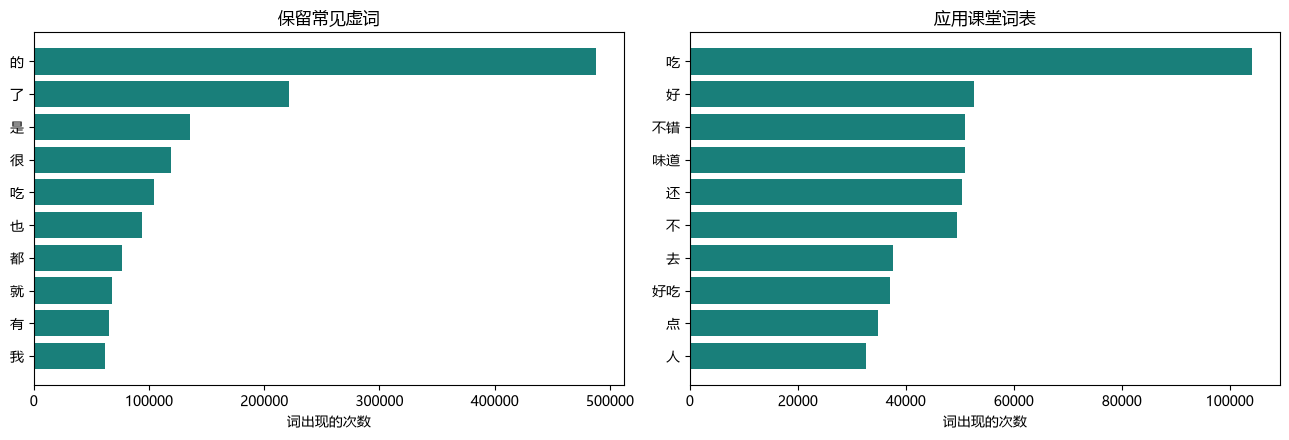

In [6]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
fonts={f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.sans-serif']=[n for n in ['Microsoft YaHei','Noto Sans CJK SC','SimHei'] if n in fonts]+['DejaVu Sans']
plt.rcParams['axes.unicode_minus']=False
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,tab,title in zip(axes,[raw_table,frequency],['保留常见虚词','应用课堂词表']):
    top=tab.head(10).iloc[::-1]
    ax.barh(top.word,top['count'],color='#197f7a')
    ax.set(title=title,xlabel='词出现的次数')
fig.tight_layout();plt.show()

## 4. 从词频到TF-IDF（课件16—25页）

先算df：一个词出现在几段里，每段最多贡献1。再算平滑IDF，最后逐格乘以原始次数。

In [7]:
document_frequency=(toy_counts>0).sum(axis=0)
display(pd.DataFrame({'词':toy_words,'df':document_frequency}))
# 整批评论也采用每条最多计一次的办法。
document_counts=Counter()
for words in kept_words:
    document_counts.update(set(words))
frequency['documents']=frequency.word.map(document_counts)
frequency=frequency[['word','count','documents','relative_frequency']]
frequency.head(12)

,词,df
0,味道,3
1,牛角包,1
2,上菜速度,1


,word,count,documents,relative_frequency
0,吃,104112,37020,0.017916
1,好,52676,29009,0.009065
2,不错,50947,27796,0.008767
3,味道,50890,27277,0.008757
4,还,50495,28046,0.008689
5,不,49514,27286,0.008520
6,去,37655,22637,0.006480
7,好吃,37036,21539,0.006373
8,点,34843,22260,0.005996
9,人,32711,21986,0.005629


### 先有df，再计算IDF与加权值

同一批文字里的每个词使用一个固定IDF，各段分别取自己的次数相乘。

In [8]:
idf=np.log((1+len(toy_texts))/(1+document_frequency))+1
weights=toy_counts*idf
display(pd.DataFrame({'词':toy_words,'df':document_frequency,'IDF':idf}))
display(pd.DataFrame(weights,index=['A','B','C'],columns=toy_words).round(3))
assert np.isclose(weights[2,1],3.386294361119891)

,词,df,IDF
0,味道,3,1.000000
1,牛角包,1,1.693147
2,上菜速度,1,1.693147


,味道,牛角包,上菜速度
A,2.0,0.000,0.000
B,1.0,0.000,1.693
C,1.0,3.386,0.000


### 让工具重做手算

固定三个词，关闭整行归一化；依次核对每个位置。实际模型沿用中文词与同一种TF-IDF公式。

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
v=TfidfVectorizer(tokenizer=tokenize,token_pattern=None,vocabulary=toy_words,norm=None)
X=v.fit_transform(toy_texts)
assert np.allclose(X.toarray(),weights)
pd.DataFrame(X.toarray(),index=['A','B','C'],columns=toy_words).round(3)

,味道,牛角包,上菜速度
A,2.0,0.000,0.000
B,1.0,0.000,1.693
C,1.0,3.386,0.000


## 5. 整理上菜速度抱怨（课件26—44页）

先读四种原标签，再把任务定义为：是否标为速度负向。只有原标签−1对应y=1，其他三类对应y=0。沿用训练、验证、测试划分。

In [10]:
y=(df['Service#Timely']==-1).astype(int)
segmented=pd.Series([' '.join(words) for words in kept_words])
train=df.split.eq('train');dev=df.split.eq('dev');test=df.split.eq('test')
print('三份样本：',train.sum(),dev.sum(),test.sum())
print('测试集真实速度负向数：',y[test].sum())

三份样本： 36850 4940 4940
测试集真实速度负向数： 261


### 学习、转换和生成概率分开运行

下面是本次固定配置，参数解释在extensions/method-card.md。课堂重点看每一行读取什么、返回什么。全部计算限制为一个线程。

In [11]:
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits
vectorizer=TfidfVectorizer(tokenizer=str.split,token_pattern=None,lowercase=False,norm=None,min_df=5,max_features=12000)
model=LogisticRegression(C=1.0,max_iter=500,solver='lbfgs',random_state=15)
with threadpool_limits(limits=1):
    X_train=vectorizer.fit_transform(segmented[train])
    model.fit(X_train,y[train])
print('训练矩阵：',X_train.shape,'；词系数数目：',model.coef_.shape[1])

训练矩阵： (36850, 12000) ；词系数数目： 12000


### 先转换验证集并核读样例（课件34—35页）

词表、IDF和系数都沿用训练结果。本次固定配置，先完成检查，再处理测试集。

In [12]:
with threadpool_limits(limits=1):
    X_dev=vectorizer.transform(segmented[dev])
    p_dev=model.predict_proba(X_dev)[:,1]
dev_rows=df.loc[dev].reset_index(drop=True)
validation=pd.DataFrame({'id':dev_rows.id,'actual':y[dev].to_numpy(),'probability':p_dev,'predicted':(p_dev>=0.5).astype(int)})
assert X_dev.shape==(4940,12000)
preview_indices=[0,int(np.flatnonzero((y[dev].to_numpy()==1)&(p_dev>=.5))[0]),int(np.flatnonzero((y[dev].to_numpy()==1)&(p_dev<.5))[0])]
display(validation.iloc[preview_indices][['id','actual','probability']])
print('训练与验证列数相同：',X_train.shape[1],X_dev.shape[1])

,id,actual,probability
0,28729,0,3.902164e-09
76,27608,1,9.999999e-01
1,19856,1,5.256381e-04


训练与验证列数相同： 12000 12000


### 读完整原文，再生成测试概率（课件36—39页）

33204包含前面的B摘句。先读同一条完整原话，再看向量、各词贡献及概率。

In [13]:
test_rows=df.loc[test].reset_index(drop=True)
rid=33204
i=int(np.flatnonzero(test_rows.id.to_numpy()==rid)[0])
print(test_rows.review.iloc[i])
with threadpool_limits(limits=1):
    X_test=vectorizer.transform(segmented[test])
    p=model.predict_proba(X_test)[:,1]
predicted=(p>=0.5).astype(int)
predictions=pd.DataFrame({'id':test_rows.id,'actual':y[test].to_numpy(),'probability':p,'predicted':predicted})
predictions.head(5)

第一次来广粥城，感觉不错，人特别的多，只有知道收银员，还要排队等好久。环境还可以，上菜速度适中，菜量很少，味道还行，菜心不错值得推荐，但是筷子要自己拿。如果服务员更专业点那就更好了。团购很实惠，还会再来的。 菜品口味大致都可以，唯独我们点的饺子馅太多了，味道不是很好，点了2份，两个人只吃了一份另外的打包回来了！


,id,actual,probability,predicted
0,13482,0,2.069978e-04,0
1,25634,0,3.672711e-08,0
2,6383,0,5.389346e-09,0
3,46407,0,1.065121e-11,0
4,15715,0,1.043995e-15,0


In [14]:
features=vectorizer.get_feature_names_out()
contribution=X_test[i].multiply(model.coef_[0]).toarray()[0]
idx=np.argsort(np.abs(contribution))[::-1][:3]
display(pd.DataFrame({'词':features[idx],'TF-IDF':X_test[i].toarray()[0][idx],'系数':model.coef_[0][idx],'贡献':contribution[idx]}))
eta=model.intercept_[0]+contribution.sum()
probability=1/(1+np.exp(-eta))
assert np.isclose(probability,p[i])
print('常数',model.intercept_[0],'；其余贡献',contribution.sum()-contribution[idx].sum())
print('η=',eta,'；概率=',probability,'；预测=',predicted[i],'；人工y=',predictions.actual.iloc[i])

,词,TF-IDF,系数,贡献
0,上菜速度,4.392578,0.741669,3.257839
1,好久,4.817604,0.673413,3.244237
2,等,2.605673,0.820256,2.137320


常数 -4.160184189155257 ；其余贡献 -3.127853014070526
η= 1.3513589445654075 ；概率= 0.7943517102028271 ；预测= 1 ；人工y= 0


### 先数四格，再算两个比例（课件40—42页）

行是真实，列是预测。精确率从预测抱怨这一列出发，召回率从真实抱怨这一行出发。

In [15]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y[test],predicted,labels=[0,1])
tn,fp,fn,tp=cm.ravel()
display(pd.DataFrame(cm,index=['真实其他0','真实抱怨1'],columns=['预测其他0','预测抱怨1']))
precision=tp/(tp+fp);recall=tp/(tp+fn)
print('精确率：',tp,'/',tp+fp,'=',round(precision,4))
print('召回率：',tp,'/',tp+fn,'=',round(recall,4))
# 同样的定义用于验证集，便于回看当前固定方案的表现。
dev_cm=confusion_matrix(y[dev],validation.predicted,labels=[0,1])
display(pd.DataFrame(dev_cm,index=['验证真实0','验证真实1'],columns=['验证预测0','验证预测1']))

,预测其他0,预测抱怨1
真实其他0,4564,115
真实抱怨1,152,109


精确率： 109 / 224 = 0.4866
召回率： 109 / 261 = 0.4176


,验证预测0,验证预测1
验证真实0,4575,112
验证真实1,155,98


## 6. 从六项体验到服务简报（课件45—51页）

总体表使用作者人工标签。逐列数提及与负向，再画图，不用模型预测替换原标签。

In [16]:
rows=[]
for column,name in ASPECTS.items():
    s=df[column]
    mentioned=int((s!=-2).sum());negative=int((s==-1).sum())
    rows.append({'name':name,'mentioned':mentioned,'negative':negative,'mention_rate':mentioned/len(df),'negative_share':negative/mentioned})
summary=pd.DataFrame(rows)
assert summary.loc[summary.name=='上菜速度','mentioned'].iloc[0]==7190
assert summary.loc[summary.name=='上菜速度','negative'].iloc[0]==2508
summary.round(4)

,name,mentioned,negative,mention_rate,negative_share
0,口味,44223,1885,0.9464,0.0426
1,上菜速度,7190,2508,0.1539,0.3488
2,服务态度,26832,4232,0.5742,0.1577
3,性价比,10397,1244,0.2225,0.1196
4,卫生,15745,1965,0.3369,0.1248
5,嘈杂情况,13488,1550,0.2886,0.1149


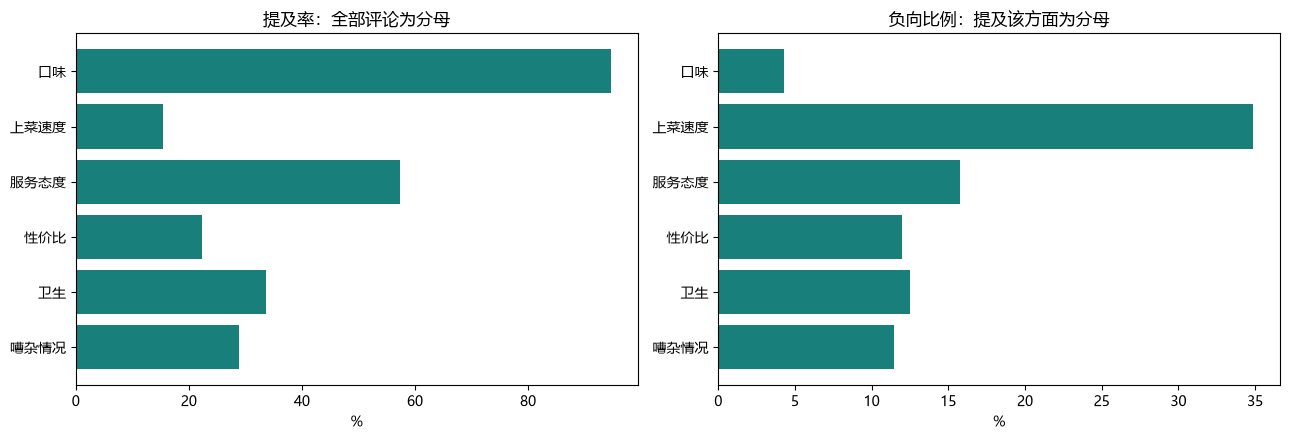

In [17]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,column,title in zip(axes,['mention_rate','negative_share'],['提及率：全部评论为分母','负向比例：提及该方面为分母']):
    ax.barh(summary.name.iloc[::-1],summary[column].iloc[::-1]*100,color='#197f7a')
    ax.set(title=title,xlabel='%')
fig.tight_layout();plt.show()

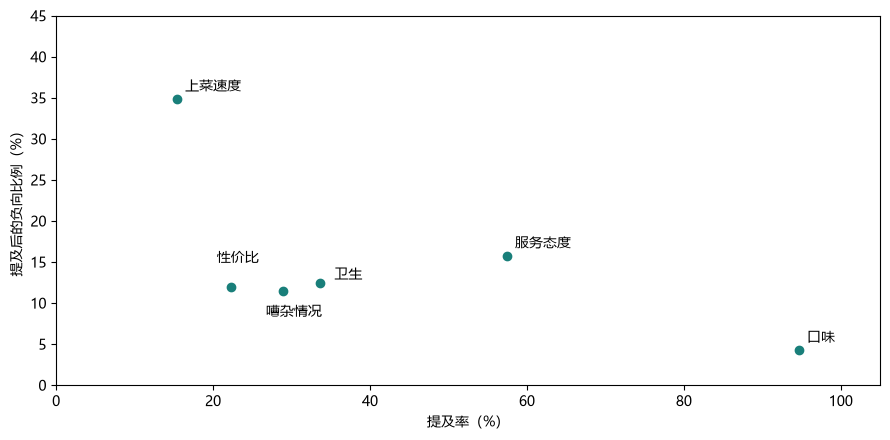

距离公司很近很近的一家东北菜饭馆，就在马路斜对面，我以前却从来没去吃过。某天领导请客，就去尝尝了。店很大，有上下两层，当然生意也是非常好的，尤其是午餐饭点的时候，周边的商务楼的都来了，一般点个菜上个菜要挺久的，催了也不快。店面比较干净，菜品也很清爽：空心菜很清爽；鸡蛋饼摊得很嫩；椒盐排条：椒盐是单独放置在小碟子里的，自己沾；农家小炒肉：不是很辣，很下饭。大概每天饭点人都很多，服务生也都习惯了吧，态度就那样了。
汉堡王（月星环球港店），在中山北路上靠近金沙江路的交叉口，周边交通方便，地铁3、4、13号线金沙江路出来，地下通道就可以直接进入月星环球港。\\n汉堡王在地下一层，下午2点左右去的还要排队，点评上团购的仙野蓝莓新地买一送一。性价比高，划算！味道也不错，甜而不腻，奶味足，赞~\\n就是服务不咋地，可能太忙了，态度不耐烦，有待改善


In [18]:
fig,ax=plt.subplots(figsize=(9,4.5))
offsets=[(6,6),(6,6),(6,6),(-10,18),(10,3),(-12,-18)]
for r,offset in zip(summary.itertuples(),offsets):
    ax.scatter(r.mention_rate*100,r.negative_share*100,color='#197f7a')
    ax.annotate(r.name,(r.mention_rate*100,r.negative_share*100),xytext=offset,textcoords='offset points')
ax.set(xlabel='提及率（%）',ylabel='提及后的负向比例（%）',xlim=(0,105),ylim=(0,45))
fig.tight_layout();plt.show()
print(df.loc[df.id==47010,'review'].iloc[0])
print(df.loc[df.id==29189,'review'].iloc[0])

## 7. 保存自己的成果与编程任务（课件50—54页）

用一个比例、一句原文、一项具体安排填写service-brief-template.md。再选择一小步交给编程助手，要求保留中间表，并用A、B、C手算核对。

In [19]:
out=Path('outputs');out.mkdir(exist_ok=True)
frequency.to_csv(out/'word-counts.csv',index=False)
raw_table.to_csv(out/'word-counts-raw.csv',index=False)
count_table.to_csv(out/'toy-counts.csv')
pd.DataFrame(weights,index=['A','B','C'],columns=toy_words).to_csv(out/'toy-weights.csv')
predictions.to_csv(out/'test-predictions.csv',index=False)
validation.to_csv(out/'validation-predictions.csv',index=False)
# 对照同一项目的完整脚本结果；上面的每一步已经独立运行。
reference=json.loads((out/'results.json').read_text(encoding='utf-8'))
assert int(word_counts['味道'])==next(r['count'] for r in reference['frequency']['top'] if r['word']=='味道')
assert tp==reference['classifier']['metrics']['tp']
assert fp==reference['classifier']['metrics']['fp']
print('词频、手算矩阵和分类计数与完整脚本一致。')

词频、手算矩阵和分类计数与完整脚本一致。


## 来源

Bu等（2021），ASAP，NAACL，2069–2079。https://aclanthology.org/2021.naacl-main.167/ 。三份原始CSV、固定版本、哈希与原许可随包提供。拓展阅读与设置见extensions/method-card.md。